# Sparse Regression and Feature Selection
Gradient Descent (GD) and Iterative Hard Thresholding (IHT) for regression and feature selection.

## Synthetic data
100 observations, 50 features, five nonzero coefficients.

In [1]:
import numpy as np


np.random.seed(50)
a = 100
b = 50
c = 5
X =np.random.randn (a,b)
t_w = np.zeros (b)
t_w[:c] = np.random.uniform(5,10,c)
np.random.shuffle(t_w)
y= X @ t_w + np.random.normal(0,0.5,a)

## Gradient descent

In [2]:
def gradient_descent(X,y, learning_rate = 0.01 , iterations= 100):
  a,b =X.shape
  w = np.zeros(b)
  history_gd = []
  for i in range(iterations):
    prediction = X @ w
    error = prediction - y
    mse = np.mean(error**2)
    history_gd.append(mse)
    gradient = (2/a) *(X.T @ error)
    w = w - learning_rate * gradient
  return w, history_gd
w_estimated, history_gd = gradient_descent(X,y, learning_rate = 0.1, iterations = 500)
print("True coefficients (first five):",t_w[:5])
print("Estimated coefficients (first five):",w_estimated[:5])

True coefficients (first five): [0.         0.         0.         0.         8.77588421]
Estimated coefficients (first five): [-0.07309658 -0.00943431  0.0615674   0.07628387  8.79939255]


## Iterative hard thresholding

In [3]:

def iterative_hard_thresholding(X,y,c,learning_rate=0.1, iterations=500):
  a,b =X.shape
  if not isinstance(c, (int, np.integer)) or not 0 <= c <= b:
    raise ValueError("c must be an integer between 0 and the number of features")
  w = np.zeros(b)
  history_arx = []
  for i in range(iterations):
    prediction = X @ w
    error = prediction - y
    mse = np.mean(error**2)
    history_arx.append(mse)
    gradient = (2/a) *(X.T @ error)
    w = w - learning_rate * gradient
    if c < b:
        # Keep exactly the top c indices, with deterministic tie-breaking.
        keep = np.argsort(-np.abs(w), kind="stable")[:c]
        mask = np.ones(b, dtype=bool)
        mask[keep] = False
        w[mask] = 0
  return w, history_arx
w_arx, history_arx = iterative_hard_thresholding(X,y,c=5, learning_rate= 0.1, iterations = 500)
print("True coefficients (first five):",t_w[:5])
print("Estimated coefficients (first five):",w_arx[:5])

True coefficients (first five): [0.         0.         0.         0.         8.77588421]
Estimated coefficients (first five): [0.         0.         0.         0.         8.73949281]


True support: [ 4  8 22 24 26]
IHT support: [ 4  8 22 24 26]
GD: training MSE = 0.1113, coefficient error = 0.5412
IHT: training MSE = 0.2198, coefficient error = 0.0755


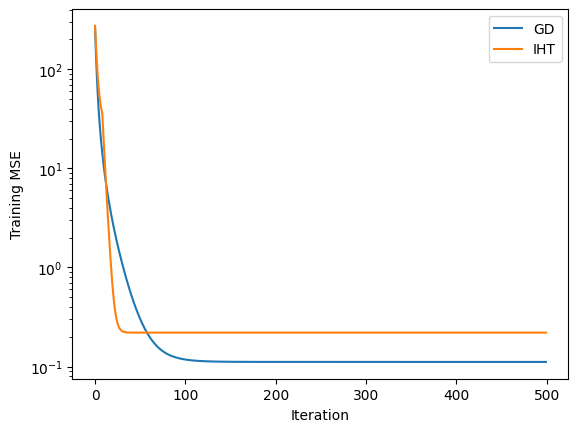

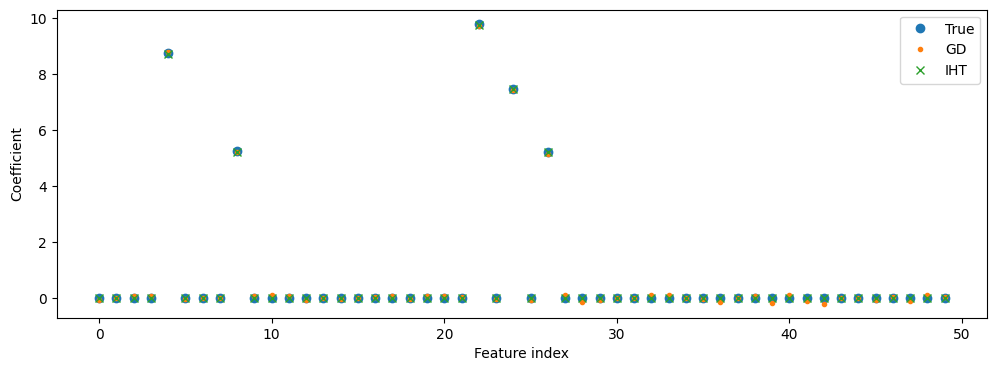

In [4]:
import matplotlib.pyplot as plt
print("True support:", np.flatnonzero(t_w))
print("IHT support:", np.flatnonzero(w_arx))
for name, w in [("GD", w_estimated), ("IHT", w_arx)]:
    print(f"{name}: training MSE = {np.mean((X @ w - y)**2):.4f}, coefficient error = {np.linalg.norm(w-t_w):.4f}")
plt.plot(history_gd, label="GD")
plt.plot(history_arx, label="IHT")
plt.yscale("log"); plt.xlabel("Iteration"); plt.ylabel("Training MSE"); plt.legend(); plt.show()
plt.figure(figsize=(12,4))
plt.plot(t_w, "o", label="True")
plt.plot(w_estimated, ".", label="GD")
plt.plot(w_arx, "x", label="IHT")
plt.xlabel("Feature index"); plt.ylabel("Coefficient"); plt.legend(); plt.show()

## Iris regression
Predict petal width. Fit scaling and target centering on training data only; use the same split for both methods.

GD test MSE: 0.0338; coefficients: [-0.1463  0.0853  0.8978]
IHT test MSE: 0.0436; coefficients: [0.     0.     0.7323]
Selected feature: petal length (cm)


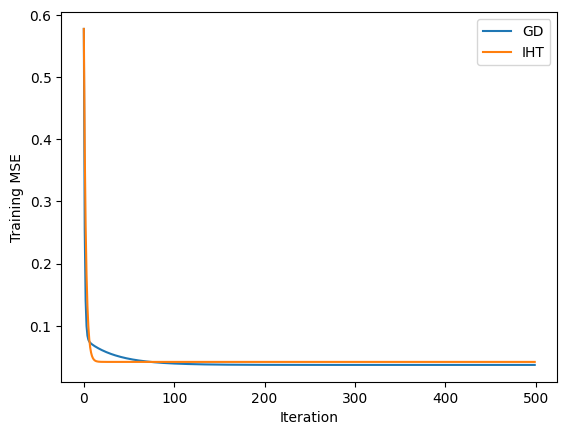

In [5]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(iris.data[:, :3], iris.data[:, 3], test_size=0.25, random_state=50)
mu, sd = X_train.mean(axis=0), X_train.std(axis=0)
X_train, X_test = (X_train-mu)/sd, (X_test-mu)/sd
intercept = y_train.mean()
y_centered = y_train-intercept
w_gd, hist_gd = gradient_descent(X_train, y_centered, learning_rate=0.1, iterations=500)
w_iht, hist_iht = iterative_hard_thresholding(X_train, y_centered, c=1, learning_rate=0.1, iterations=500)
for name, w in [("GD", w_gd), ("IHT", w_iht)]:
    pred = intercept + X_test @ w
    print(f"{name} test MSE: {np.mean((pred-y_test)**2):.4f}; coefficients: {w.round(4)}")
print("Selected feature:", iris.feature_names[np.argmax(np.abs(w_iht))])
plt.plot(hist_gd, label="GD"); plt.plot(hist_iht, label="IHT")
plt.xlabel("Iteration"); plt.ylabel("Training MSE"); plt.legend(); plt.show()

In [6]:
# Small regression checks for edge cases.
for cardinality in (0, 1, 2):
    weights, _ = iterative_hard_thresholding(np.eye(2), np.ones(2), c=cardinality, iterations=3)
    assert np.count_nonzero(weights) <= cardinality
print("Cardinality checks passed.")

Cardinality checks passed.
